In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import case, func

csv_path = "utility_scale_storage_reviewed_adaptive_V2.csv"
df_csv = pd.read_csv(csv_path, sep=None, engine="python")

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,          # applications
    TLS202_APPLN_TITLE,    # titles
    TLS203_APPLN_ABSTR,    # abstracts
    TLS206_PERSON,         # persons (applicants and inventors)
    TLS207_PERS_APPLN,     # person <-> application links
    TLS224_APPLN_CPC,      # CPC classification
)

patstat = PatstatClient(env="PROD")
db = patstat.orm()

family_ids = (
    df_csv["docdb_family_id"]
    .dropna()
    .astype(int)
    .unique()
    .tolist()
)

chunks = []
for i in range(0, len(family_ids), 10000):
    batch = family_ids[i : i + 10000]
    q = (
        db.query(
            TLS201_APPLN.appln_id,
            TLS201_APPLN.docdb_family_id,
            TLS201_APPLN.appln_auth,
            TLS201_APPLN.appln_filing_year,
            TLS201_APPLN.earliest_filing_year,
            TLS201_APPLN.docdb_family_size,
            TLS201_APPLN.granted,
        )
        .filter(TLS201_APPLN.appln_id < 900000000)
        .filter(TLS201_APPLN.docdb_family_id.in_(batch))
    )
    chunks.append(patstat.df(q))

df_utility = pd.concat(chunks, ignore_index=True)

print(f"df_utility pronto: {len(df_utility):,} applications su {df_utility['docdb_family_id'].nunique():,} famiglie.")
display(df_utility.head())


df_utility pronto: 8,649 applications su 6,838 famiglie.


,appln_id,docdb_family_id,appln_auth,appln_filing_year,earliest_filing_year,docdb_family_size,granted
0,647283278,99228194,CN,2025,2025,1,N
1,634641377,80458714,US,2022,2021,5,N
2,610085153,84423391,CN,2023,2022,4,N
3,487935332,60718073,CN,2017,2017,1,Y
4,640754495,97707429,CN,2025,2025,1,Y


## Patents offices

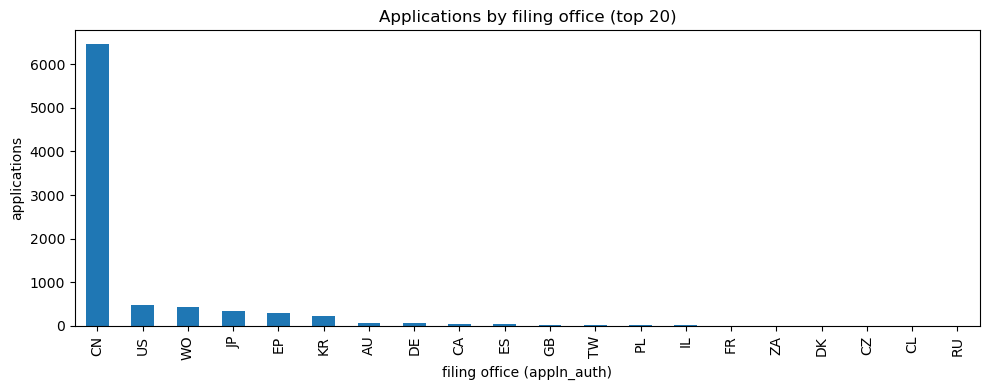

In [2]:
by_auth = (
    df_utility.groupby("appln_auth", as_index=False)["appln_id"]
    .count()
    .rename(columns={"appln_id": "applications"})
    .sort_values("applications", ascending=False)
    .head(20)
)


# Bar chart of the 20 offices with most applications
ax = by_auth.plot.bar(x="appln_auth", y="applications", legend=False, figsize=(10, 4))
ax.set_xlabel("filing office (appln_auth)")
ax.set_ylabel("applications")
ax.set_title("Applications by filing office (top 20)")
plt.tight_layout()
plt.show()

,All Applications,International (size > 1),% International
appln_auth,,,
CN,6454,484,7.5
US,480,460,95.8
WO,439,419,95.4
JP,344,240,69.8
EP,304,295,97.0
KR,221,126,57.0
AU,72,71,98.6
DE,70,62,88.6
CA,51,51,100.0


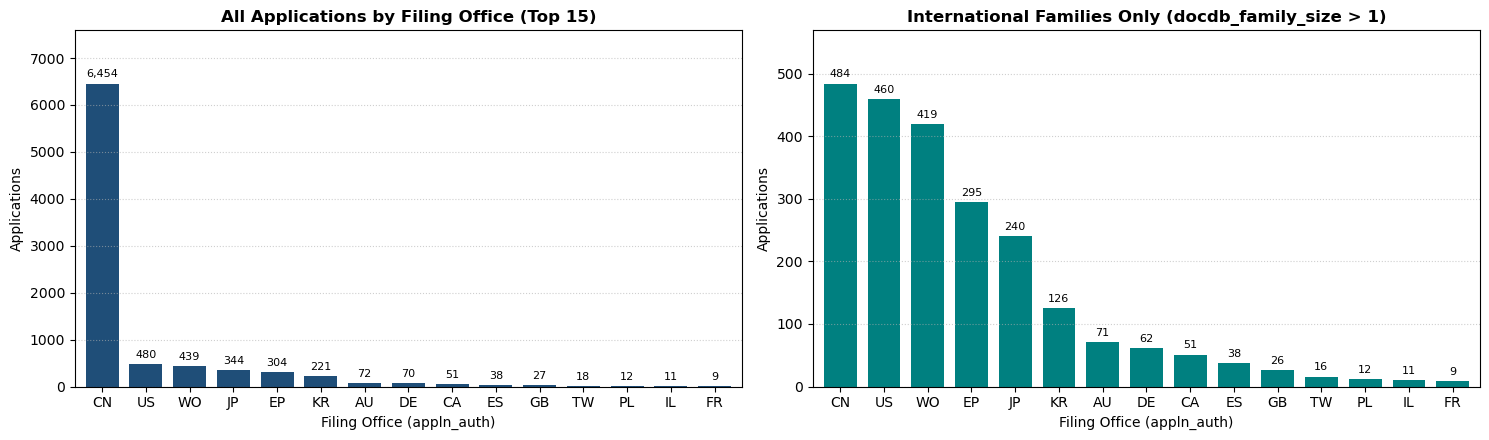

In [3]:
# ==============================================================================
# TOP FILING OFFICES: ALL APPLICATIONS VS. INTERNATIONAL FAMILIES (SIZE > 1)
# ==============================================================================

top_all = (
    df_utility.groupby("appln_auth")["appln_id"]
    .count()
    .sort_values(ascending=False)
    .head(15)
)

# (docdb_family_size > 1)
df_intl = df_utility[df_utility["docdb_family_size"] > 1]
top_intl = (
    df_intl.groupby("appln_auth")["appln_id"]
    .count()
    .sort_values(ascending=False)
    .head(15)
)

summary_offices = pd.DataFrame({
    "All Applications": df_utility.groupby("appln_auth")["appln_id"].count(),
    "International (size > 1)": df_intl.groupby("appln_auth")["appln_id"].count(),
}).fillna(0).astype(int)

summary_offices["% International"] = (
    (summary_offices["International (size > 1)"] / summary_offices["All Applications"]) * 100
).round(1)

display(summary_offices.sort_values("All Applications", ascending=False).head(10))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.5))

top_all.plot.bar(ax=ax1, color="#1f4e78", width=0.75)
ax1.set_title("All Applications by Filing Office (Top 15)", fontweight="bold")
ax1.set_xlabel("Filing Office (appln_auth)")
ax1.set_ylabel("Applications")
ax1.grid(axis="y", linestyle=":", alpha=0.6)
ax1.tick_params(axis="x", rotation=0)

top_intl.plot.bar(ax=ax2, color="#008080", width=0.75)
ax2.set_title("International Families Only (docdb_family_size > 1)", fontweight="bold")
ax2.set_xlabel("Filing Office (appln_auth)")
ax2.set_ylabel("Applications")
ax2.grid(axis="y", linestyle=":", alpha=0.6)
ax2.tick_params(axis="x", rotation=0)


for ax in (ax1, ax2):
    for p in ax.patches:
        ax.annotate(
            f"{int(p.get_height()):,}",
            (p.get_x() + p.get_width() / 2.0, p.get_height()),
            ha="center",
            va="bottom",
            fontsize=8,
            xytext=(0, 3),
            textcoords="offset points",
        )
    ax.set_ylim(0, ax.get_ylim()[1] * 1.12)

plt.tight_layout()
plt.show()

In [4]:
chunks = []
for i in range(0, len(family_ids), 10000):
    batch = family_ids[i : i + 10000]
    q = (
        db.query(
            TLS201_APPLN.ipr_type,
            TLS201_APPLN.appln_kind,
            func.count(TLS201_APPLN.appln_id).label("applications"),
        )
        .filter(TLS201_APPLN.appln_id < 900000000)
        .filter(TLS201_APPLN.docdb_family_id.in_(batch))
        .group_by(TLS201_APPLN.ipr_type, TLS201_APPLN.appln_kind)
    )
    chunks.append(patstat.df(q))

ipr_summary = (
    pd.concat(chunks, ignore_index=True)
    .groupby(["ipr_type", "appln_kind"], as_index=False)["applications"]
    .sum()
    .sort_values("applications", ascending=False)
    .head(15)
)

display(ipr_summary)


,ipr_type,appln_kind,applications
0,PI,A,7043
3,UM,U,1094
2,PI,W,439
1,PI,T,73


In [5]:
IP5 = ["CN", "EP", "JP", "KR", "US"]

chunks = []
for i in range(0, len(family_ids), 10000):
    batch = family_ids[i : i + 10000]
    q = (
        db.query(
            TLS201_APPLN.appln_auth,
            TLS201_APPLN.ipr_type,
            func.count(TLS201_APPLN.appln_id).label("applications"),
        )
        .filter(TLS201_APPLN.appln_auth.in_(IP5))
        .filter(TLS201_APPLN.appln_id < 900000000)
        .filter(TLS201_APPLN.docdb_family_id.in_(batch))
        .group_by(TLS201_APPLN.appln_auth, TLS201_APPLN.ipr_type)
    )
    chunks.append(patstat.df(q))

ipr = (
    pd.concat(chunks, ignore_index=True)
    .groupby(["appln_auth", "ipr_type"], as_index=False)["applications"]
    .sum()
)


# One row per office, one column per IPR type, values as shares of the office total
ipr_share = ipr.pivot(index="appln_auth", columns="ipr_type", values="applications").fillna(0)
ipr_share = ipr_share.div(ipr_share.sum(axis=1), axis=0).round(3)
ipr_share

ipr_type,PI,UM
appln_auth,,
CN,0.833,0.167
EP,1.000,0.000
JP,0.988,0.012
KR,1.000,0.000
US,1.000,0.000


## Dates

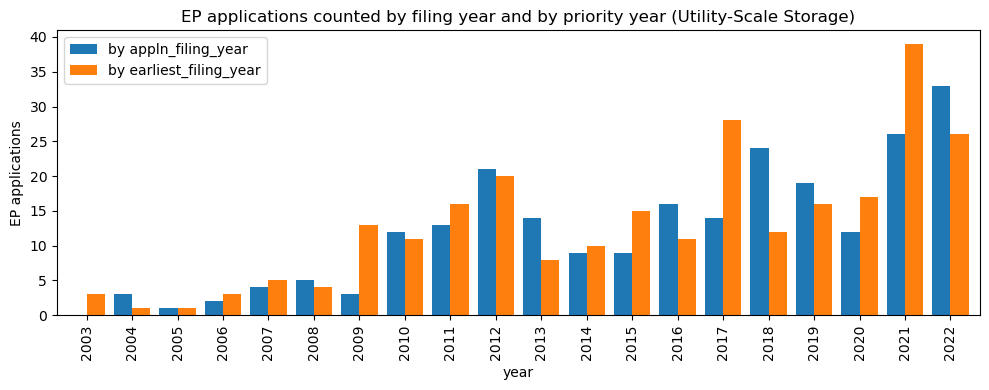

Min earliest_filing_year (all offices): 2001
Min appln_filing_year (all offices):    2003


In [6]:
# Filter df_utility to EP applications only (no additional SQL queries needed)
df_ep = df_utility[df_utility["appln_auth"] == "EP"]

by_filing = (
    df_ep[df_ep["appln_filing_year"].between(2003, 2022)]
    .groupby("appln_filing_year")["appln_id"]
    .count()
)

by_priority = (
    df_ep[df_ep["earliest_filing_year"].between(2003, 2022)]
    .groupby("earliest_filing_year")["appln_id"]
    .count()
)

# Align both series side by side across the full 2002-2022 range
years = (
    pd.DataFrame({
        "by appln_filing_year": by_filing,
        "by earliest_filing_year": by_priority,
    })
    .reindex(range(2003, 2023))
    .fillna(0)
    .astype(int)
)

ax = years.plot.bar(figsize=(10, 4), width=0.8)
ax.set_xlabel("year")
ax.set_ylabel("EP applications")
ax.set_title("EP applications counted by filing year and by priority year (Utility-Scale Storage)")
plt.tight_layout()
plt.show()

print("Min earliest_filing_year (all offices):", df_utility["earliest_filing_year"].min())
print("Min appln_filing_year (all offices):   ", df_utility["appln_filing_year"].min())


## Number of offices

In [7]:
# One row per family for priority years 2015-2020 (computed directly on df_utility)
fam = (
    df_utility[df_utility["earliest_filing_year"].between(2015, 2020)]
    .groupby("docdb_family_id", as_index=False)["docdb_family_size"]
    .max()
)

display(fam["docdb_family_size"].describe())

count    1522.000000
mean        1.405388
std         1.797228
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max        51.000000
Name: docdb_family_size, dtype: float64

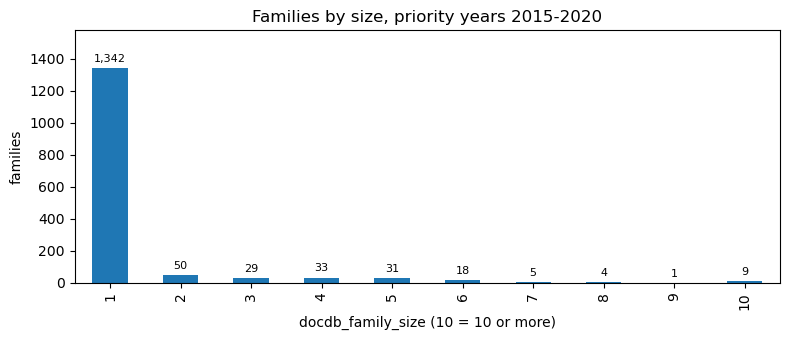

In [8]:
# Distribution of family size, capped at 10 for readability
sizes = fam["docdb_family_size"].clip(upper=10).value_counts().sort_index()

ax = sizes.plot.bar(figsize=(8, 3.5))
ax.set_xlabel("docdb_family_size (10 = 10 or more)")
ax.set_ylabel("families")
ax.set_title("Families by size, priority years 2015-2020")

for p in ax.patches:
    ax.annotate(
        f"{int(p.get_height()):,}",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="bottom",
        fontsize=8,
        xytext=(0, 3),
        textcoords="offset points",
    )
ax.set_ylim(0, ax.get_ylim()[1] * 1.12)

plt.tight_layout()
plt.show()

## Granted

In [9]:
IP5 = ["CN", "EP", "JP", "KR", "US"]

# Query grant counts for Patents of Invention (PI) filed in 2010-2015 across IP5 offices
chunks = []
for i in range(0, len(family_ids), 10000):
    batch = family_ids[i : i + 10000]
    q = (
        db.query(
            TLS201_APPLN.appln_auth,
            func.count(TLS201_APPLN.appln_id).label("applications"),
            func.sum(case((TLS201_APPLN.granted == "Y", 1), else_=0)).label("granted"),
        )
        .filter(TLS201_APPLN.appln_id < 900000000)
        .filter(TLS201_APPLN.docdb_family_id.in_(batch))
        .filter(TLS201_APPLN.appln_auth.in_(IP5))
        .filter(TLS201_APPLN.ipr_type == "PI")
        .filter(TLS201_APPLN.appln_filing_year.between(2010, 2015))
        .group_by(TLS201_APPLN.appln_auth)
    )
    chunks.append(patstat.df(q))

# Aggregate across batches and compute the grant rate per office
grants = (
    pd.concat(chunks, ignore_index=True)
    .groupby("appln_auth", as_index=False)[["applications", "granted"]]
    .sum()
    .astype({"applications": int, "granted": int})
)

grants["grant_rate"] = (grants["granted"] / grants["applications"]).round(3)
display(grants.sort_values("grant_rate", ascending=False))


,appln_auth,applications,granted,grant_rate
4,US,120,101,0.842
1,EP,78,53,0.679
0,CN,278,185,0.665
2,JP,125,81,0.648
3,KR,56,36,0.643


In [10]:
# Query forward citation counts per DOCDB family for priority years 2010-2015
chunks = []
for i in range(0, len(family_ids), 10000):
    batch = family_ids[i : i + 10000]
    q = (
        db.query(
            TLS201_APPLN.docdb_family_id,
            TLS201_APPLN.earliest_filing_year,
            func.max(TLS201_APPLN.nb_citing_docdb_fam).label("nb_citing_docdb_fam"),
        )
        .filter(TLS201_APPLN.appln_id < 900000000)
        .filter(TLS201_APPLN.docdb_family_id.in_(batch))
        .filter(TLS201_APPLN.earliest_filing_year.between(2010, 2015))
        .group_by(TLS201_APPLN.docdb_family_id, TLS201_APPLN.earliest_filing_year)
    )
    chunks.append(patstat.df(q))

# Ensure one row per family across batches
cit = (
    pd.concat(chunks, ignore_index=True)
    .groupby(["docdb_family_id", "earliest_filing_year"], as_index=False)["nb_citing_docdb_fam"]
    .max()
)

# For each priority year: family count, mean, median and share of families cited at least once
summary = cit.groupby("earliest_filing_year")["nb_citing_docdb_fam"].agg(
    families="count",
    mean="mean",
    median="median",
    share_cited=lambda s: (s > 0).mean(),
).round(2)

display(summary)

,families,mean,median,share_cited
earliest_filing_year,,,,
2010,37,27.95,12.0,1.00
2011,63,16.33,10.0,0.97
2012,78,12.23,9.0,0.95
2013,93,13.24,7.0,0.95
2014,112,11.04,7.0,0.96
2015,141,10.40,7.0,0.91


In [11]:
IP5 = ["CN", "EP", "JP", "KR", "US"]

# Query applicant and inventor counts for 2015-2020 applications across IP5 offices
chunks = []
for i in range(0, len(family_ids), 10000):
    batch = family_ids[i : i + 10000]
    q = (
        db.query(
            TLS201_APPLN.appln_auth,
            func.count(TLS201_APPLN.appln_id).label("applications"),
            func.sum(case((TLS201_APPLN.nb_applicants == 0, 1), else_=0)).label("zero_applicants"),
            func.sum(TLS201_APPLN.nb_inventors).label("sum_inventors"),
        )
        .filter(TLS201_APPLN.appln_id < 900000000)
        .filter(TLS201_APPLN.docdb_family_id.in_(batch))
        .filter(TLS201_APPLN.appln_auth.in_(IP5))
        .filter(TLS201_APPLN.appln_filing_year.between(2015, 2020))
        .group_by(TLS201_APPLN.appln_auth)
    )
    chunks.append(patstat.df(q))

# Aggregate across batches and compute exact shares and averages per office
team = (
    pd.concat(chunks, ignore_index=True)
    .groupby("appln_auth", as_index=False)[["applications", "zero_applicants", "sum_inventors"]]
    .sum()
)

team["share_zero_applicants"] = (team["zero_applicants"] / team["applications"]).round(3)
team["avg_inventors"] = (team["sum_inventors"] / team["applications"]).round(2)

# Select and sort final summary columns
team = team[["appln_auth", "applications", "zero_applicants", "share_zero_applicants", "avg_inventors"]]
display(team.sort_values("applications", ascending=False))

,appln_auth,applications,zero_applicants,share_zero_applicants,avg_inventors
0,CN,1359,0,0.000,5.31
4,US,157,0,0.000,3.14
2,JP,137,11,0.080,2.61
1,EP,94,0,0.000,2.86
3,KR,87,1,0.011,2.28


## CPC classification

In [12]:
# Extract unique application IDs from df_utility
appln_ids = df_utility["appln_id"].unique().tolist()

# Inspect CPC symbol formatting and fixed-width padding on our dataset
q = (
    db.query(
        TLS224_APPLN_CPC.appln_id,
        TLS224_APPLN_CPC.cpc_class_symbol,
        func.length(TLS224_APPLN_CPC.cpc_class_symbol).label("length"),
        func.replace(TLS224_APPLN_CPC.cpc_class_symbol, " ", "").label("symbol_without_blanks"),
    )
    .filter(TLS224_APPLN_CPC.appln_id.in_(appln_ids[:1000]))
    .limit(10)
)

display(patstat.df(q))

,appln_id,cpc_class_symbol,length,symbol_without_blanks
0,638916319,H02S 50/00,11,H02S50/00
1,501537568,Y02E 40/10,11,Y02E40/10
2,496172629,Y02E 70/30,11,Y02E70/30
3,477829820,H10F 19/00,11,H10F19/00
4,639597849,Y02E 10/20,11,Y02E10/20
5,645006595,H02J2103/35,11,H02J2103/35
6,484672174,H01M 10/48,11,H01M10/48
7,503406815,H02J 7/34,11,H02J7/34
8,599902215,H02J2101/24,11,H02J2101/24
9,546213046,H02B 1/301,12,H02B1/301


In [13]:
# Normalize CPC symbols by removing positional blank spaces
symbol_no_blanks = func.replace(TLS224_APPLN_CPC.cpc_class_symbol, " ", "")
appln_ids = df_utility["appln_id"].unique().tolist()

# Fetch all CPC symbols linked to applications in df_utility
cpc_chunks = []
for i in range(0, len(appln_ids), 10000):
    batch = appln_ids[i : i + 10000]
    q = (
        db.query(
            TLS224_APPLN_CPC.appln_id,
            symbol_no_blanks.label("cpc_symbol"),
        )
        .filter(TLS224_APPLN_CPC.appln_id.in_(batch))
    )
    cpc_chunks.append(patstat.df(q))

df_cpc = pd.concat(cpc_chunks, ignore_index=True).drop_duplicates()

# Extract the CPC main-group prefix (everything up to and including '/')
df_cpc["cpc_main_group"] = df_cpc["cpc_symbol"].str.split("/").str[0] + "/"

# Merge with docdb_family_id and rank the top 15 CPC main groups in df_utility
top_cpc = (
    df_cpc.merge(df_utility[["appln_id", "docdb_family_id"]].drop_duplicates(), on="appln_id")
    .groupby("cpc_main_group", as_index=False)
    .agg(
        applications=("appln_id", "nunique"),
        families=("docdb_family_id", "nunique"),
    )
    .sort_values("families", ascending=False)
    .head(15)
)

display(top_cpc)

,cpc_main_group,applications,families
483,H02J3/,5042,4095
568,Y02E60/,2918,1711
486,H02J7/,2225,1448
563,Y02E10/,1915,1441
478,H02J2101/,1661,1312
479,H02J2103/,1273,1215
569,Y02E70/,1542,1156
475,H02J15/,1082,771
423,G06Q50/,549,500
446,H01M10/,965,448


In [14]:
# Use "H02J3/" (top grid-integration group) or "Y02E60/" (top pure energy-storage group)
CPC_PREFIX = "H02J3/"

# Reuse df_cpc already in memory (no extra SQL query needed)
matched_ids = set(df_cpc.loc[df_cpc["cpc_symbol"].str.startswith(CPC_PREFIX), "appln_id"])

# Count distinct applications and families by filing office
cpc_offices = (
    df_utility[df_utility["appln_id"].isin(matched_ids)]
    .groupby("appln_auth", as_index=False)
    .agg(
        applications=("appln_id", "nunique"),
        families=("docdb_family_id", "nunique"),
    )
    .sort_values("families", ascending=False)
    .head(10)
)

display(cpc_offices)

,appln_auth,applications,families
5,CN,3951,3895
31,WO,254,252
30,US,265,204
8,EP,162,154
17,KR,153,144
16,JP,101,95
0,AU,45,43
9,ES,19,19
6,DE,18,17
3,CA,17,16


In [15]:
# Count distinct CPC symbols per application using df_cpc already in memory (no SQL query needed)
n_sym = (
    df_cpc.groupby("appln_id", as_index=False)["cpc_symbol"]
    .count()
    .rename(columns={"cpc_symbol": "n_symbols"})
)

display(n_sym["n_symbols"].describe())

# Check how many applications in df_utility have zero CPC symbols assigned
total_apps = df_utility["appln_id"].nunique()
covered_apps = n_sym["appln_id"].nunique()
missing_cpc = total_apps - covered_apps
print(f"Applications with CPC: {covered_apps:,} / {total_apps:,} ({covered_apps / total_apps:.1%})")
print(f"Applications without CPC: {missing_cpc:,} ({missing_cpc / total_apps:.1%})")

count    7504.000000
mean        8.116871
std         7.098407
min         1.000000
25%         4.000000
50%         7.000000
75%        10.000000
max        54.000000
Name: n_symbols, dtype: float64

Applications with CPC: 7,504 / 8,649 (86.8%)
Applications without CPC: 1,145 (13.2%)


In [16]:
# Merge application metadata with normalized CPC symbols already in memory 
app_cpc = (
    df_utility[["appln_id", "docdb_family_id", "appln_auth", "docdb_family_size"]]
    .drop_duplicates()
    .merge(df_cpc[["appln_id", "cpc_symbol"]], on="appln_id", how="inner")
)

# Select one family with size >= 3 and at least two applications carrying CPC symbols
multi_app_families = (
    app_cpc[app_cpc["docdb_family_size"] >= 3]
    .groupby("docdb_family_id")["appln_id"]
    .nunique()
)
example_family = multi_app_families[multi_app_families >= 2].index[0]

fam_cpc = app_cpc[app_cpc["docdb_family_id"] == example_family]

# Build a presence matrix: one row per application, one column per CPC symbol
cpc_matrix = pd.crosstab(
    fam_cpc["appln_auth"] + " " + fam_cpc["appln_id"].astype(str),
    fam_cpc["cpc_symbol"],
    rownames=["application"],
    colnames=["cpc_symbol"],
).replace({1: "X", 0: ""})

print(f"Example DOCDB family ID: {example_family}")
display(cpc_matrix)

# Top 15 full CPC symbols ranked by applications (with distinct family count alongside)
top_full_cpc = (
    app_cpc.groupby("cpc_symbol", as_index=False)
    .agg(
        applications=("appln_id", "nunique"),
        families=("docdb_family_id", "nunique"),
    )
    .sort_values("applications", ascending=False)
    .head(15)
)

display(top_full_cpc)

Example DOCDB family ID: 34312732


cpc_symbol,B60L53/00,B60L58/10,B60L58/20,B60L58/21,H01M10/052,H01M10/0525,H01M10/06,H01M10/425,H01M10/44,H01M16/00,...,H02J7/34,H02J7/342,H02J7/50,H02J7/855,H02J7/96,H02J7/977,Y02E60/10,Y02T10/70,Y02T10/7072,Y02T90/14
application,,,,,,,,,,,,,,,,,,,,,
CA 4921074,X,X,X,X,X,X,X,X,X,X,...,X,X,X,X,X,X,X,X,X,X
CN 8049605,X,X,X,X,X,X,X,X,X,X,...,X,X,X,X,X,X,X,X,X,X
EP 303842,X,X,X,X,X,X,X,X,X,X,...,X,X,X,X,X,X,X,X,X,X
JP 340553216,X,X,X,X,X,X,X,X,X,X,...,X,X,X,X,X,X,X,X,X,X
JP 340553220,X,X,X,X,X,X,X,X,X,X,...,X,X,X,X,X,X,X,X,X,X
JP 39503375,X,X,X,X,X,X,X,X,X,X,...,X,X,X,X,X,X,X,X,X,X
TW 45238050,X,X,X,X,X,X,X,X,X,X,...,X,X,X,X,X,X,X,X,X,X
US 45727351,X,X,X,X,X,X,X,X,X,X,...,X,X,X,X,X,X,X,X,X,X
US 52578509,X,X,X,X,X,X,X,X,X,X,...,X,X,X,X,X,X,X,X,X,X


,cpc_symbol,applications,families
1871,H02J3/32,4096,3318
2353,Y02E60/16,1595,1055
2358,Y02E70/30,1542,1156
1876,H02J3/381,1351,994
1806,H02J2103/30,1138,1085
2350,Y02E60/10,1070,525
1801,H02J2101/24,1044,772
2330,Y02E10/56,1024,846
1869,H02J3/28,752,692
1803,H02J2101/28,747,625


## Title and Abstract

In [18]:
# Extract unique application IDs already in memory from df_utility
appln_ids = df_utility["appln_id"].unique().tolist()

# Query title languages in batches to avoid full-table scans and SQL IN-clause limits
title_chunks = []
for i in range(0, len(appln_ids), 10000):
    batch = appln_ids[i : i + 10000]
    q = (
        db.query(
            TLS202_APPLN_TITLE.appln_title_lg,
            func.count(TLS202_APPLN_TITLE.appln_id).label("applications"),
        )
        .filter(TLS202_APPLN_TITLE.appln_id.in_(batch))
        .group_by(TLS202_APPLN_TITLE.appln_title_lg)
    )
    title_chunks.append(patstat.df(q))

title_lg = (
    pd.concat(title_chunks, ignore_index=True)
    .groupby("appln_title_lg", as_index=False)["applications"]
    .sum()
    .sort_values("applications", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

# Query abstract languages in batches
abstract_chunks = []
for i in range(0, len(appln_ids), 10000):
    batch = appln_ids[i : i + 10000]
    q = (
        db.query(
            TLS203_APPLN_ABSTR.appln_abstract_lg,
            func.count(TLS203_APPLN_ABSTR.appln_id).label("applications"),
        )
        .filter(TLS203_APPLN_ABSTR.appln_id.in_(batch))
        .group_by(TLS203_APPLN_ABSTR.appln_abstract_lg)
    )
    abstract_chunks.append(patstat.df(q))

abstract_lg = (
    pd.concat(abstract_chunks, ignore_index=True)
    .groupby("appln_abstract_lg", as_index=False)["applications"]
    .sum()
    .sort_values("applications", ascending=False)
    .head(10)
    .reset_index(drop=True)
)

# Display the two language rankings side by side
display(pd.concat([title_lg, abstract_lg], axis=1, keys=["titles", "abstracts"]))

titles                      abstracts             
  appln_title_lg applications appln_abstract_lg applications
0             en         8409                en         8309
1             ja           87                ja           77
2             de           63                de           64
3             es           26                es           41
4             ko           15                ko           32
5             fr           14                fr           14
6             da            8                ru            3
7             pt            6                zh            3
8             it            3                pt            3
9             zh            3                fi            1

In [19]:
IP5 = ["CN", "EP", "JP", "KR", "US"]

# Filter 2015-2020 IP5 applications already in memory from df_utility
ip5_apps = (
    df_utility[
        df_utility["appln_auth"].isin(IP5)
        & df_utility["appln_filing_year"].between(2015, 2020)
    ][["appln_id", "appln_auth"]]
    .drop_duplicates()
    .copy()
)

target_ids = ip5_apps["appln_id"].tolist()

# Query title languages in batches for the filtered applications
title_chunks = []
for i in range(0, len(target_ids), 10000):
    batch = target_ids[i : i + 10000]
    q = (
        db.query(
            TLS202_APPLN_TITLE.appln_id,
            TLS202_APPLN_TITLE.appln_title_lg,
        )
        .filter(TLS202_APPLN_TITLE.appln_id.in_(batch))
    )
    title_chunks.append(patstat.df(q))

df_titles_lg = pd.concat(title_chunks, ignore_index=True).drop_duplicates()

# Flag applications with any title and with an English title
has_any_title = set(df_titles_lg["appln_id"])
has_en_title = set(df_titles_lg.loc[df_titles_lg["appln_title_lg"] == "en", "appln_id"])

ip5_apps["with_title"] = ip5_apps["appln_id"].isin(has_any_title).astype(int)
ip5_apps["with_english_title"] = ip5_apps["appln_id"].isin(has_en_title).astype(int)

# Aggregate by filing office without multi-language row duplication
titles = (
    ip5_apps.groupby("appln_auth", as_index=False)
    .agg(
        applications=("appln_id", "nunique"),
        with_title=("with_title", "sum"),
        with_english_title=("with_english_title", "sum"),
    )
    .sort_values("applications", ascending=False)
)
titles["share_english"] = (titles["with_english_title"] / titles["applications"]).round(3)

display(titles)

# Inspect 5 sample English titles and abstracts from df_utility
sample_ids = df_utility["appln_id"].unique().tolist()[:1000]
q_sample = (
    db.query(
        TLS203_APPLN_ABSTR.appln_id,
        TLS202_APPLN_TITLE.appln_title,
        TLS203_APPLN_ABSTR.appln_abstract,
    )
    .join(TLS202_APPLN_TITLE, TLS202_APPLN_TITLE.appln_id == TLS203_APPLN_ABSTR.appln_id)
    .filter(TLS203_APPLN_ABSTR.appln_id.in_(sample_ids))
    .filter(TLS203_APPLN_ABSTR.appln_abstract_lg == "en")
    .filter(TLS202_APPLN_TITLE.appln_title_lg == "en")
    .limit(5)
)

display(patstat.df(q_sample))

,appln_auth,applications,with_title,with_english_title,share_english
0,CN,1359,1359,1359,1.000
4,US,157,157,157,1.000
2,JP,137,137,112,0.818
1,EP,94,94,94,1.000
3,KR,87,87,81,0.931


,appln_id,appln_title,appln_abstract
0,633358575,Configuration method of energy storage system ...,The invention relates to the technical field o...
1,538486472,Method and system for battery energy storage t...,The invention discloses a method and a system ...
2,620142696,Flywheel energy storage charging and dischargi...,The invention discloses a flywheel energy stor...
3,621017867,Wind-solar-salt-cavern flow battery energy sto...,The invention discloses a wind-solar-salt-cave...
4,503427367,COMPRESSED AIR STORAGE POWER GENERATOR,PROBLEM TO BE SOLVED: To effectively prevent t...


## Applicant and Inventor

In [20]:
# Define role flags in TLS207_PERS_APPLN (seq_nr > 0 indicates an active role)
is_applicant = TLS207_PERS_APPLN.applt_seq_nr > 0
is_inventor = TLS207_PERS_APPLN.invt_seq_nr > 0

# Filter target applications directly from df_utility (no SQL join with TLS201_APPLN needed)
ep_apps = df_utility[
    (df_utility["appln_auth"] == "EP")
    & (df_utility["appln_filing_year"].between(2015, 2020))
][["appln_id"]].drop_duplicates()

ep_ids = ep_apps["appln_id"].tolist()

# Query applicant and inventor counts per application in batches
chunks = []
for i in range(0, len(ep_ids), 10000):
    batch = ep_ids[i : i + 10000]
    q = (
        db.query(
            TLS207_PERS_APPLN.appln_id,
            func.count(case((is_applicant, 1))).label("n_applicants"),
            func.count(case((is_inventor, 1))).label("n_inventors"),
        )
        .filter(TLS207_PERS_APPLN.appln_id.in_(batch))
        .group_by(TLS207_PERS_APPLN.appln_id)
    )
    chunks.append(patstat.df(q))

# Left-merge onto ep_apps so applications with zero person links are preserved as 0
per_appln = (
    ep_apps.merge(pd.concat(chunks, ignore_index=True), on="appln_id", how="left")
    .fillna({"n_applicants": 0, "n_inventors": 0})
    .astype({"n_applicants": int, "n_inventors": int})
)

display(per_appln[["n_applicants", "n_inventors"]].describe().round(2))

,n_applicants,n_inventors
count,94.00,94.00
mean,1.02,2.86
std,0.15,1.65
min,1.00,1.00
25%,1.00,2.00
50%,1.00,3.00
75%,1.00,4.00
max,2.00,8.00


In [21]:
# Compute the share of EP 2015-2020 applications with co-applicants (2+ applicants)
print("Share of applications with 2+ applicants:", round((per_appln["n_applicants"] > 1).mean(), 3))

# Define combined applicant/inventor roles in TLS207_PERS_APPLN
role = case(
    ((TLS207_PERS_APPLN.applt_seq_nr > 0) & (TLS207_PERS_APPLN.invt_seq_nr > 0), "applicant and inventor"),
    (TLS207_PERS_APPLN.applt_seq_nr > 0, "applicant only"),
    (TLS207_PERS_APPLN.invt_seq_nr > 0, "inventor only"),
    else_="neither",
)

# Extract unique application IDs from df_utility to avoid scanning the full table
appln_ids = df_utility["appln_id"].unique().tolist()

# Query person-application role counts in batches
chunks = []
for i in range(0, len(appln_ids), 10000):
    batch = appln_ids[i : i + 10000]
    q = (
        db.query(
            role.label("role"),
            func.count().label("person_application_links"),
        )
        .filter(TLS207_PERS_APPLN.appln_id.in_(batch))
        .group_by(role)
    )
    chunks.append(patstat.df(q))

# Aggregate role counts across batches and calculate percentage shares
role_summary = (
    pd.concat(chunks, ignore_index=True)
    .groupby("role", as_index=False)["person_application_links"]
    .sum()
    .sort_values("person_application_links", ascending=False)
)
role_summary["share"] = (
    role_summary["person_application_links"] / role_summary["person_application_links"].sum()
).round(3)

display(role_summary)

Share of applications with 2+ applicants: 0.021


,role,person_application_links,share
2,inventor only,45907,0.797
1,applicant only,10975,0.191
0,applicant and inventor,716,0.012


## Names

In [22]:
# Extract unique application IDs from df_utility
appln_ids = df_utility["appln_id"].unique().tolist()

# Fetch applicant records from TLS207_PERS_APPLN and TLS206_PERSON for our dataset
app_chunks = []
for i in range(0, len(appln_ids), 10000):
    batch = appln_ids[i : i + 10000]
    q = (
        db.query(
            TLS207_PERS_APPLN.appln_id,
            TLS207_PERS_APPLN.person_id,
            TLS207_PERS_APPLN.applt_seq_nr,
            TLS206_PERSON.person_name,
            TLS206_PERSON.doc_std_name,
            TLS206_PERSON.psn_name,
            TLS206_PERSON.psn_level,
            TLS206_PERSON.han_name,
            TLS206_PERSON.han_harmonized,
            TLS206_PERSON.person_ctry_code,
            TLS206_PERSON.psn_sector,
        )
        .join(TLS206_PERSON, TLS207_PERS_APPLN.person_id == TLS206_PERSON.person_id)
        .filter(TLS207_PERS_APPLN.appln_id.in_(batch))
        .filter(TLS207_PERS_APPLN.applt_seq_nr > 0)
    )
    app_chunks.append(patstat.df(q))

df_applicants = pd.concat(app_chunks, ignore_index=True)

# Automatically pick the top harmonized applicant (han_name) in df_utility
top_han = (
    df_applicants[df_applicants["han_name"].notna() & (df_applicants["han_name"].str.strip() != "")]
    .groupby("han_name")["appln_id"]
    .nunique()
    .sort_values(ascending=False)
    .index[0]
)

print(f"Selected top harmonized applicant in dataset: {top_han}")

# Inspect raw vs harmonized name variants for the selected organization
name_variants = (
    df_applicants[df_applicants["han_name"] == top_han][
        ["person_name", "doc_std_name", "psn_name", "psn_level", "han_name", "han_harmonized"]
    ]
    .drop_duplicates()
    .head(15)
)

display(name_variants)

Selected top harmonized applicant in dataset: STATE GRID CORPORATION OF CHINA


,person_name,doc_std_name,psn_name,psn_level,han_name,han_harmonized
1128,STATE GRID CORPORATION OF CHINA,STATE GRID CORP CHINA,SGCC(STATE GRID CORPORATION OF CHINA),2,STATE GRID CORPORATION OF CHINA,0


In [23]:
# Compare how psn_name consolidates variants that han_name leaves unharmonized (han_harmonized == 0)
sgcc_variants = (
    df_applicants[df_applicants["psn_name"] == "SGCC(STATE GRID CORPORATION OF CHINA)"][
        ["person_name", "doc_std_name", "psn_name", "psn_level", "han_name", "han_harmonized"]
    ]
    .drop_duplicates()
    .head(15)
)

display(sgcc_variants)

,person_name,doc_std_name,psn_name,psn_level,han_name,han_harmonized
193,STATE GRID CORPORATION OF CHNA,CHINA ELECTRIC POWER RES INST,SGCC(STATE GRID CORPORATION OF CHINA),2,STATE GRID CORP OF CHINA,2
870,"CHINA ELECTRIC POWER RESEARCH INSTITUTE CO., LTD.",CHINA ELECTRIC POWER RES INST CO LTD,SGCC(STATE GRID CORPORATION OF CHINA),2,CHINA ELECT POWER RESEARCH INSTITUTE,2
1128,STATE GRID CORPORATION OF CHINA,STATE GRID CORP CHINA,SGCC(STATE GRID CORPORATION OF CHINA),2,STATE GRID CORPORATION OF CHINA,0
1558,"CHINA ELECTRIC POWER RESEARCH INSTITUTE CO., LTD.",CHINA ELECTRIC POWER RES INST CO LTD,SGCC(STATE GRID CORPORATION OF CHINA),2,"CHINA ELECTRIC POWER RESEARCH INSTITUTE CO., LTD.",0
2079,CHINA ELECTRIC POWER RESEARCH INSTITUTE,CHINA ELECTRIC POWER RES INST,SGCC(STATE GRID CORPORATION OF CHINA),2,CHINA ELECT POWER RESEARCH INSTITUTE,2
2499,"STATE GRID CORPORATION OF CHINA, NORTHWEST BRANCH",STATE GRID CORP OF CHINA NORTHWEST BRANCH,SGCC(STATE GRID CORPORATION OF CHINA),2,"STATE GRID CORPORATION OF CHINA, NORTHWEST BRANCH",0
2626,EAST CHINA BRANCH OF STATE GRID CORPORATION OF...,EAST CHINA BRANCH OF STATE GRID CORP OF CHINA,SGCC(STATE GRID CORPORATION OF CHINA),2,EAST CHINA BRANCH OF STATE GRID CORPORATION OF...,0
3913,NORTHWEST BRANCH OF STATE GRID CORPORATION OF ...,NORTHWEST BRANCH OF STATE GRID CORP OF CHINA,SGCC(STATE GRID CORPORATION OF CHINA),2,NORTHWEST BRANCH OF STATE GRID CORPORATION OF ...,0
3991,STATE GRID CORPORATION OF CHINA,STATE GRID CORP CHINA,SGCC(STATE GRID CORPORATION OF CHINA),2,STATE GRID CORP OF CHINA,2
5735,NORTHEAST BRANCH OF STATE GRID CORPORATION OF ...,NORTHEAST BRANCH OF STATE GRID CORP OF CHINA,SGCC(STATE GRID CORPORATION OF CHINA),2,NORTHEAST BRANCH OF STATE GRID CORPORATION OF ...,0


In [24]:
IP5_WO = ["CN", "EP", "JP", "KR", "US", "WO"]

# Filter target applications (IP5 + WO) already in memory from df_utility
target_apps = (
    df_utility[df_utility["appln_auth"].isin(IP5_WO)][["appln_id", "appln_auth"]]
    .drop_duplicates()
)
target_ids = target_apps["appln_id"].tolist()

# Handle missing country codes ("  ", empty string, or NULL) and missing addresses
missing_ctry = (TLS206_PERSON.person_ctry_code.is_(None)) | (
    func.trim(TLS206_PERSON.person_ctry_code) == ""
)
missing_addr = (TLS206_PERSON.person_address.is_(None)) | (
    func.trim(TLS206_PERSON.person_address) == ""
)

# Query person-link counts and missing geography per application in batches
chunks = []
for i in range(0, len(target_ids), 10000):
    batch = target_ids[i : i + 10000]
    q = (
        db.query(
            TLS207_PERS_APPLN.appln_id,
            func.count().label("person_links"),
            func.sum(case((missing_ctry, 1), else_=0)).label("missing_country"),
            func.sum(case((missing_addr, 1), else_=0)).label("missing_address"),
        )
        .select_from(TLS207_PERS_APPLN)
        .join(TLS206_PERSON, TLS207_PERS_APPLN.person_id == TLS206_PERSON.person_id)
        .filter(TLS207_PERS_APPLN.appln_id.in_(batch))
        .group_by(TLS207_PERS_APPLN.appln_id)
    )
    chunks.append(patstat.df(q))

# Merge with filing office metadata and aggregate by appln_auth
ctry = (
    target_apps.merge(pd.concat(chunks, ignore_index=True), on="appln_id", how="inner")
    .groupby("appln_auth", as_index=False)[["person_links", "missing_country", "missing_address"]]
    .sum()
)

ctry["share_missing_country"] = (ctry["missing_country"] / ctry["person_links"]).round(3)
ctry["share_missing_address"] = (ctry["missing_address"] / ctry["person_links"]).round(3)

display(ctry.sort_values("share_missing_country", ascending=False))

,appln_auth,person_links,missing_country,missing_address,share_missing_country,share_missing_address
0,CN,48846,48827,48846,1.000,1.000
2,JP,1008,1008,1008,1.000,1.000
3,KR,800,274,800,0.342,1.000
5,WO,2026,114,2014,0.056,0.994
4,US,2219,2,1863,0.001,0.840
1,EP,1202,0,1000,0.000,0.832


In [25]:
# Merge applicant sector metadata with filing office info already in memory (no SQL query needed)
app_sectors = (
    df_applicants[["appln_id", "psn_sector"]]
    .drop_duplicates()
    .merge(
        df_utility[["appln_id", "docdb_family_id", "appln_auth"]].drop_duplicates(),
        on="appln_id",
        how="inner",
    )
)

# Filter for European Patent Office (EP) applications across the dataset
ep_sectors = app_sectors[app_sectors["appln_auth"] == "EP"].copy()
ep_sectors["psn_sector"] = (
    ep_sectors["psn_sector"].fillna("").str.strip().replace("", "UNKNOWN")
)

# Aggregate distinct applications and DOCDB families by institutional sector
sector_summary = (
    ep_sectors.groupby("psn_sector", as_index=False)
    .agg(
        applications=("appln_id", "nunique"),
        families=("docdb_family_id", "nunique"),
    )
    .sort_values("applications", ascending=False)
    .reset_index(drop=True)
)
sector_summary["share"] = (
    sector_summary["applications"] / ep_sectors["appln_id"].nunique()
).round(3)

display(sector_summary)

,psn_sector,applications,families,share
0,COMPANY,197,188,0.648
1,UNKNOWN,92,89,0.303
2,INDIVIDUAL,8,8,0.026
3,GOV NON-PROFIT,6,6,0.020
4,UNIVERSITY,2,2,0.007
5,GOV NON-PROFIT UNIVERSITY,1,1,0.003


In [26]:
# Extract unique application IDs already in memory from df_utility
appln_ids = df_utility["appln_id"].unique().tolist()

# Query distinct (person_id, nuts_level) pairs linked to our dataset in batches
nuts_chunks = []
for i in range(0, len(appln_ids), 10000):
    batch = appln_ids[i : i + 10000]
    q = (
        db.query(
            TLS206_PERSON.person_id,
            TLS206_PERSON.nuts_level,
        )
        .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.person_id == TLS206_PERSON.person_id)
        .filter(TLS207_PERS_APPLN.appln_id.in_(batch))
        .distinct()
    )
    nuts_chunks.append(patstat.df(q))

# Deduplicate persons across batches and summarize NUTS regional granularity
df_nuts = pd.concat(nuts_chunks, ignore_index=True).drop_duplicates(subset=["person_id"])
nuts_summary = (
    df_nuts.groupby("nuts_level", dropna=False, as_index=False)["person_id"]
    .count()
    .rename(columns={"person_id": "persons"})
    .sort_values("nuts_level")
    .reset_index(drop=True)
)
nuts_summary["share"] = (nuts_summary["persons"] / nuts_summary["persons"].sum()).round(3)

display(nuts_summary)

# Top 15 EP applicants (2015-2020) computed in memory from df_utility and df_applicants
year_col = "earliest_filing_year" if "earliest_filing_year" in df_utility.columns else "appln_filing_year"

ep_subset = df_utility[
    (df_utility["appln_auth"] == "EP")
    & (df_utility[year_col].between(2015, 2020))
][["appln_id", "docdb_family_id"]].drop_duplicates()

ep_applicants = ep_subset.merge(
    df_applicants[["appln_id", "psn_name", "han_name", "person_name", "person_ctry_code", "psn_sector"]],
    on="appln_id",
    how="inner",
)

# Use psn_name as primary entity identifier with fallback to han_name/person_name
ep_applicants["applicant_name"] = (
    ep_applicants["psn_name"]
    .fillna("")
    .str.strip()
    .replace("", pd.NA)
    .fillna(ep_applicants["han_name"].fillna("").str.strip().replace("", pd.NA))
    .fillna(ep_applicants["person_name"].fillna("").str.strip())
)
ep_applicants["person_ctry_code"] = ep_applicants["person_ctry_code"].fillna("").str.strip().replace("", "UNKNOWN")
ep_applicants["psn_sector"] = ep_applicants["psn_sector"].fillna("").str.strip().replace("", "UNKNOWN")

top_ep_applicants = (
    ep_applicants.groupby(["applicant_name", "person_ctry_code", "psn_sector"], as_index=False)
    .agg(
        families=("docdb_family_id", "nunique"),
        applications=("appln_id", "nunique"),
    )
    .sort_values(["families", "applications"], ascending=False)
    .head(15)
    .reset_index(drop=True)
)

display(top_ep_applicants)

,nuts_level,persons,share
0,0,791,0.024
1,3,142,0.004
2,9,31823,0.972


,applicant_name,person_ctry_code,psn_sector,families,applications
0,KOBE STEEL,JP,COMPANY,19,20
1,LSIS COMPANY,KR,COMPANY,5,5
2,"Huawei Digital Power Technologies Co., Ltd.",CN,UNKNOWN,3,5
3,HYDROSTOR,CA,COMPANY,3,4
4,GS YUASA INTERNATIONAL,JP,COMPANY,3,3
5,ABB SCHWEIZ,CH,COMPANY,2,2
6,CARL FREUDENBERG,DE,COMPANY,2,2
7,GE (GENERAL ELECTRIC COMPANY),US,COMPANY,2,2
8,IFPEN (IFP ENERGIES NOUVELLES),FR,GOV NON-PROFIT,2,2
9,JSYOUNGTECH COMPANY,KR,COMPANY,2,2
